# 01 · Ingesta y agregación: de 44 millones de viajes a una serie estación × hora

**Objetivo.** Entender qué datos entran al modelo: cuántos viajes hay, por qué se modelan 250 estaciones y qué forma tiene la demanda.

La agregación pesada la hace `ingesta.py` con DuckDB (lee los CSV mensuales en streaming y agrupa por estación y hora). Este notebook trabaja sobre el resultado (`data/procesados/demanda_horaria.parquet`) y sobre `reports/seleccion_estaciones.json`, que resume el conteo de viajes crudos.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from demanda_citibike.config import PROCESADOS, REPORTES, FIGURAS

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
AZUL, NARANJA, AQUA, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#333333"
res = json.loads((REPORTES / "resultados.json").read_text(encoding="utf-8"))

In [2]:
demanda = pd.read_parquet(PROCESADOS / "demanda_horaria.parquet")
meta = pd.read_csv(PROCESADOS / "estaciones.csv", dtype={"estacion": str})
sel = json.loads((REPORTES / "seleccion_estaciones.json").read_text(encoding="utf-8"))

horas = demanda.groupby("estacion").size()
print(f"Filas estación-hora : {len(demanda):,}")
print(f"Estaciones          : {demanda['estacion'].nunique()}  ×  {horas.iloc[0]:,} h (2024 es bisiesto: 366 × 24)")
print(f"Periodo             : {demanda['fecha_hora'].min()} → {demanda['fecha_hora'].max()}")
print(f"Salidas modeladas   : {demanda['salidas'].sum():,}")
print()
print(f"Viajes 2024 (todos) : {sel['viajes_2024']:,} en {sel['estaciones_con_salidas']:,} estaciones de origen")
print(f"Cuota de las 250    : {sel['cuota_salidas_modeladas_pct']} % de los viajes")

Filas estación-hora : 2,196,000
Estaciones          : 250  ×  8,784 h (2024 es bisiesto: 366 × 24)
Periodo             : 2024-01-01 00:00:00 → 2024-12-31 23:00:00
Salidas modeladas   : 18,176,018

Viajes 2024 (todos) : 44,302,799 en 2,378 estaciones de origen
Cuota de las 250    : 41.0 % de los viajes


## ¿Por qué 250 estaciones?

La ficha pedía 200–300 estaciones con más actividad. Se eligen por **salidas totales en 2024**. Dos comprobaciones:

* **Cobertura:** las 250 concentran una parte grande del sistema con solo ~10 % de las estaciones.
* **Fuga por selección:** elegirlas con el año completo usa información de diciembre (el mes de test). Se comparó con la selección que se habría hecho con enero–noviembre.

In [3]:
print(f"Estación n.º 1   : {sel['salidas_anuales_estacion_1']:,} salidas en el año")
print(f"Estación n.º 250 : {sel['salidas_anuales_estacion_250']:,} salidas en el año")
print(f"Mediana de todas : {sel['mediana_salidas_anuales_todas']:,.0f} salidas en el año")
print(f"Coinciden {sel['coinciden_si_se_elige_con_ene_nov']} de 250 si la selección se hace solo con enero–noviembre")

Estación n.º 1   : 163,490 salidas en el año
Estación n.º 250 : 50,301 salidas en el año
Mediana de todas : 8,248 salidas en el año
Coinciden 247 de 250 si la selección se hace solo con enero–noviembre


La estación 250 tiene unas 6 veces más salidas que la estación mediana del sistema: el modelo está pensado para las estaciones donde el rebalanceo importa más, y **no** representa a las pequeñas. Como 247 de 250 estaciones coinciden con la selección sin diciembre, el sesgo de selección por mirar el mes de test es despreciable.

## Estaciones más activas

In [4]:
top = (demanda.groupby("estacion")["salidas"].sum().sort_values(ascending=False).head(10)
       .rename("salidas_2024").reset_index().merge(meta[["estacion", "nombre"]], on="estacion", how="left"))
top

,estacion,salidas_2024,nombre
0,6140.05,163490,W 21 St & 6 Ave
1,6450.05,140701,8 Ave & W 31 St
2,5905.14,140018,University Pl & E 14 St
3,5329.03,135965,West St & Chambers St
4,5788.13,134509,Lafayette St & E 8 St
5,6331.01,128284,W 31 St & 7 Ave
6,5905.12,128196,Broadway & E 14 St
7,6726.01,127606,11 Ave & W 41 St
8,6173.08,120923,Broadway & W 25 St
9,6948.10,116991,NaN


## Forma de la demanda: estación del año, semana y hora

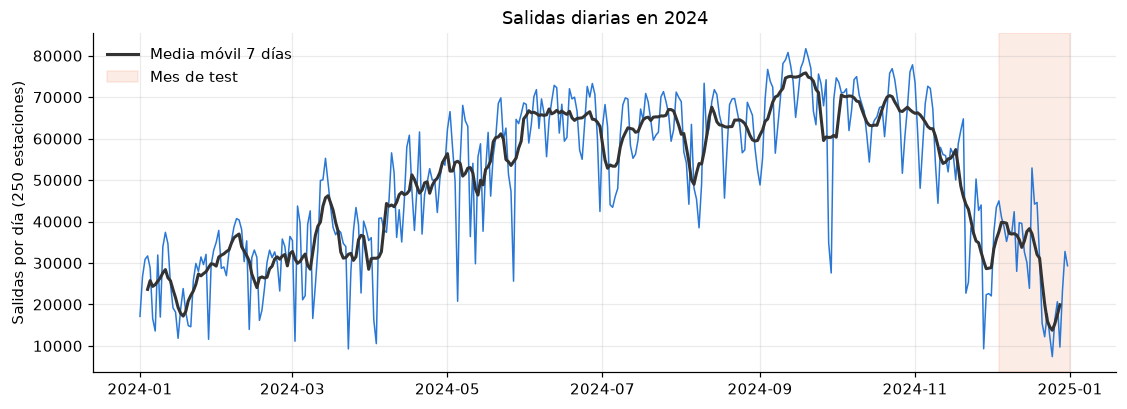

Día con más salidas : 2024-09-19 (81,707)
Día con menos salidas: 2024-12-25 (7,414)


In [5]:
diaria = demanda.groupby(demanda["fecha_hora"].dt.date)["salidas"].sum()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(pd.to_datetime(diaria.index), diaria.values, color=AZUL, linewidth=1)
ax.plot(pd.to_datetime(diaria.index), diaria.rolling(7, center=True).mean(), color=GRIS, linewidth=2, label="Media móvil 7 días")
ax.axvspan(pd.Timestamp("2024-12-03 23:00"), pd.Timestamp("2024-12-31 23:00"), color=NARANJA, alpha=0.12, label="Mes de test")
ax.set_ylabel("Salidas por día (250 estaciones)")
ax.set_title("Salidas diarias en 2024")
ax.legend(frameon=False)
plt.show()
print(f"Día con más salidas : {diaria.idxmax()} ({diaria.max():,})")
print(f"Día con menos salidas: {diaria.idxmin()} ({diaria.min():,})")

La demanda tiene una **estacionalidad anual** fuerte (verano alto, invierno bajo) y caídas bruscas en días concretos (tormentas, feriados). El mes de test (diciembre) cae en la parte baja y en plena temporada de fiestas: es más difícil que el resto del año, y conviene recordarlo al leer las métricas.

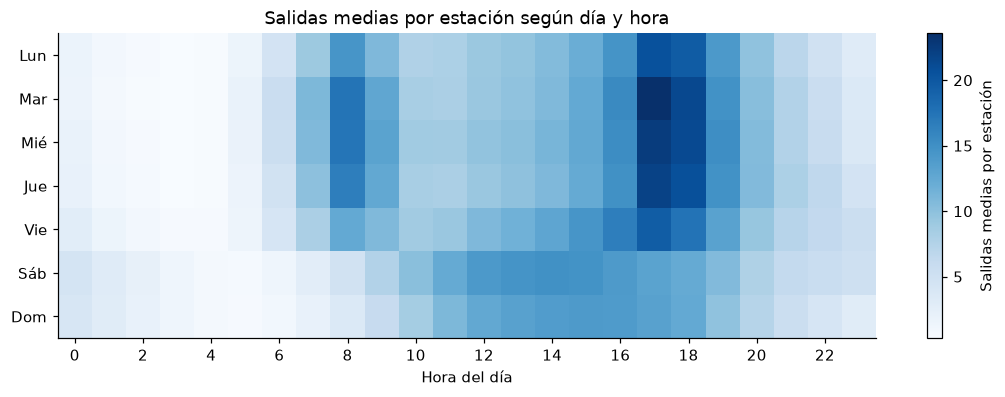

In [6]:
demanda["hora"] = demanda["fecha_hora"].dt.hour
demanda["dia_semana"] = demanda["fecha_hora"].dt.day_of_week
mapa = demanda.pivot_table(index="dia_semana", columns="hora", values="salidas", aggfunc="mean")
fig, ax = plt.subplots(figsize=(12, 3.6))
im = ax.imshow(mapa.values, aspect="auto", cmap="Blues")
ax.set_yticks(range(7), ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"])
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hora del día")
ax.grid(False)
fig.colorbar(im, ax=ax, label="Salidas medias por estación")
ax.set_title("Salidas medias por estación según día y hora")
plt.show()

Los días laborales tienen dos picos (≈ 8 h y ≈ 17–18 h, viajes al trabajo); el fin de semana tiene una sola meseta al mediodía. Por eso el modelo necesita la interacción **hora × día de semana × estación**, que un modelo global de árboles aprende directamente.

In [7]:
ceros = (demanda["salidas"] == 0).mean() * 100
por_hora_cero = demanda.groupby("hora")["salidas"].apply(lambda s: (s == 0).mean() * 100)
print(f"Horas-estación con 0 salidas: {ceros:.1f} %")
print("Porcentaje de ceros por hora (madrugada vs pico):")
print(por_hora_cero.round(1).loc[[2, 3, 4, 8, 17, 18]].to_string())

Horas-estación con 0 salidas: 17.4 %
Porcentaje de ceros por hora (madrugada vs pico):
hora
2     57.0
3     67.4
4     67.2
8      5.9
17     3.1
18     3.1


Hay muchas horas con cero salidas, concentradas de madrugada. Con tantos ceros el MAPE se vuelve infinito; por eso se usa **WAPE** (Σ|error| / Σ real).

## Ubicación de las 250 estaciones

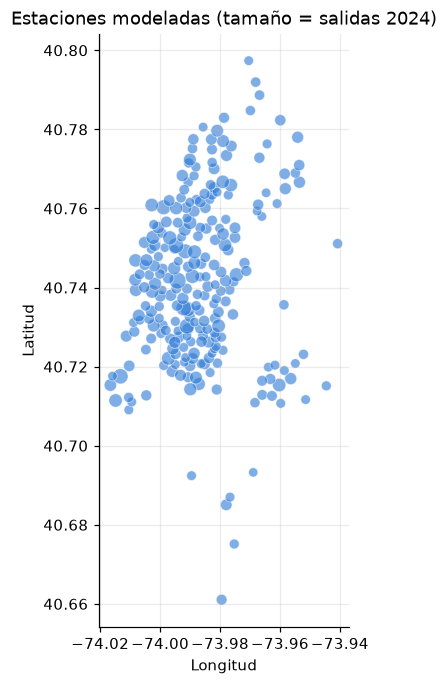

In [8]:
vol = demanda.groupby("estacion")["salidas"].sum().rename("salidas").reset_index().merge(meta, on="estacion")
fig, ax = plt.subplots(figsize=(6, 7))
ax.scatter(vol["longitud"], vol["latitud"], s=vol["salidas"] / vol["salidas"].max() * 120, color=AZUL, alpha=0.6, edgecolor="white", linewidth=0.5)
ax.set_aspect(1 / np.cos(np.deg2rad(40.75)))
ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud")
ax.set_title("Estaciones modeladas (tamaño = salidas 2024)")
plt.show()

Las estaciones modeladas se concentran en Manhattan por debajo de Central Park y en zonas cercanas de Brooklyn y Queens: es donde el sistema tiene más uso. La app de Streamlit tiene el mismo mapa sobre OpenStreetMap con el error del modelo por estación.

**Conclusión.** La tabla de modelado tiene 250 estaciones × 8 784 horas, sin huecos (las horas sin viajes son ceros explícitos). Las 250 estaciones cubren el 41 % de los viajes de 2024, y su selección casi no depende del mes de test.